In [ ]:
# simplified version of ~/analysis/run12/data/plotting/052725_efficiency_corrected_batch50000.ipynb

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import uproot
import warnings
import glob
warnings.filterwarnings('ignore')

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename):
    return (uproot.open(filename)["MatchedTree"]).arrays(observables, library='pd')

In [4]:
def addNewBranches(inputDataframe):
    df_temp = inputDataframe
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp['a'].mask(df_temp.a<1e-4, 7.9e-5, inplace=True)
    df_temp.eval('loga=log10(a)', inplace=True)
    return df_temp

In [8]:
def get_eff(ob, binedges, truth_cut, file = inputFiles[0]):
    df = applyCut(addNewBranches(getData(observables+observabless, file)), truth_cut)
    match_miss, _ = np.histogram(df[ob], bins=binedges, weights=df['w'])
    match, _ = np.histogram(df[(df.pts>15)&(df.w<5e-9)][ob], bins=binedges, weights=df[(df.pts>15)&(df.w<5e-9)]['w'])
    return match/(1e-50+match_miss)

In [6]:
def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])       
    if density:
        hist /= weights.sum()
        errs /= weights.sum()   
    return hist, errs, bins

# Read in prior

In [7]:
observables = ['pt','q','m','rg','zg','mg','w']
observabless = ['pts']#,'qs','ms','rgs','zgs','mgs']
inputFiles = ['/nfs/roberts/home/ys668/output/run12/all050124_rc_hadcorr05_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_eff096_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_tow104_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_hadcorr05_notrueptcons.root']
df1 = applyCut(getData(observables+observabless, inputFiles[0]), 'pt>0 and pts>0 and w<5e-9')
df1 = addNewBranches(df1)

# Read in unfolded

In [9]:
for it in range(1,9):
    filelist = glob.glob("/nfs/roberts/scratch/pi_hlc7/ys668/test_101326/it"+str(it)+'_*')
    if (it == 1):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, low_memory=False)
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_seed" + seed_id
        df1[column_name] = np.asarray(df_temp['weight'])

Each iteration has 1 trials.


# Obtain unfolded distribution and do efficiency correction

In [13]:
def get_seed_unc(df, it, ob, binedges, seed_string = "_seed"):
    ys = []
    rels_stat_err = []
    diff_ys_y = []
    for column_name in df.columns:
        if column_name.startswith("w_it" + str(it) + seed_string):
            ys.append(np.histogram(df[ob], bins=binedges, weights=df[column_name], density=True)[0])
            rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
                               np.histogram(df[ob], bins=binedges, weights=df[column_name], density=False)[0])
    y = np.median(ys, axis=0)
    y_err = 1.253*np.std(ys, axis=0)/np.sqrt(100)
    print("relative uncertainty from NN:", y_err/y)
    
    for i in range(len(ys)):
        diff_ys_y.append(abs(ys[i] - y))
    diff_ys_y = np.array(diff_ys_y)   
    y_stat_err = []
    for i in range(len(binedges)-1):
        trial_index = np.where(diff_ys_y[:,i] == min(diff_ys_y[:,i]))[0][0] # for bin i, which seed gives the y closest to the median?
        y_stat_err.append(rels_stat_err[trial_index][i]*y[i])
    print("relative uncertainty from stat:", y_stat_err/y)
    
    return y, y_err, y_stat_err

In [15]:
def process_ob_nom(ob_index):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    df1_cut = applyCut(df1, cut)
    
    y_arr = []
    err_arr = []
    
    for it in range(1,9):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(df1_cut, it, ob, binedges)
        if (it == 102):
            y_mc_bs, err_mc_bs = get_mc_bs_unc(df1_cut, it, ob, binedges)
            y_data_bs, err_data_bs = get_data_bs_unc(df1_cut, it, ob, binedges)
        else:
            y_mc_bs = np.ones(len(y_seed))
            err_mc_bs = np.zeros(len(y_seed))
            y_data_bs = np.ones(len(y_seed))
            err_data_bs = np.zeros(len(y_seed))
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )
        print('total (stat + NN + MC bootstrap + data bootstrap):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        eff = get_eff(ob, binedges, cut)
        y_scaled = y_seed/(1e-50+eff)
        err_scaled = err/(1e-50+eff)
        
        y_arr.append(y_scaled/sum(y_scaled))
        err_arr.append(err_scaled/sum(y_scaled))
     
    return x, y_arr, err_arr

# $Q$

In [11]:
obs = ['q','q','q','q','q']
binedgess = [np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-0.8,1.2,0.4)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60', '40<pt<60']

In [27]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
# x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
# x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
# x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01314236 0.00952303 0.00710445 0.00571771 0.00510213 0.00482849
 0.00491529 0.00558473 0.00682181 0.00948387]
total (stat + NN + MC bootstrap + data bootstrap): [0.01314236 0.00952303 0.00710445 0.00571771 0.00510213 0.00482849
 0.00491529 0.00558473 0.00682181 0.00948387]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01312376 0.0095398  0.00711742 0.00573051 0.00511067 0.00483827
 0.00492318 0.00559269 0.00682653 0.00949017]
total (stat + NN + MC bootstrap + data bootstrap): [0.01312376 0.0095398  0.00711742 0.00573051 0.00511067 0.00483827
 0.00492318 0.00559269 0.00682653 0.00949017]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01315715 0.00957963 0.0071451  0.00574887 0.00512425 0.00485131
 0.0049356  0.00560675 0.00684022 0.0095044 ]
t

In [28]:
mean_20_25 = y_arr[1]
err_20_25 = err_arr[1]

In [29]:
x, y_arr, err_arr = process_ob_nom(1)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01942022 0.01168118 0.0088252  0.00696034 0.00630896 0.00581964
 0.00600569 0.00659268 0.00814167 0.01138758]
total (stat + NN + MC bootstrap + data bootstrap): [0.01942022 0.01168118 0.0088252  0.00696034 0.00630896 0.00581964
 0.00600569 0.00659268 0.00814167 0.01138758]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.0194306  0.0117096  0.00883378 0.00697949 0.00631619 0.00584155
 0.0060165  0.00660427 0.00814289 0.01141069]
total (stat + NN + MC bootstrap + data bootstrap): [0.0194306  0.0117096  0.00883378 0.00697949 0.00631619 0.00584155
 0.0060165  0.00660427 0.00814289 0.01141069]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.0195571  0.01176302 0.00885341 0.00700928 0.00632563 0.00586629
 0.00603791 0.00663556 0.00815413 0.01143687]
t

In [30]:
mean_25_30 = y_arr[1]
err_25_30 = err_arr[1]

In [31]:
x, y_arr, err_arr = process_ob_nom(2)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02558612 0.01608121 0.01142961 0.00885458 0.00758198 0.0069494
 0.00708069 0.00784507 0.00992041 0.0149709 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.02558612 0.01608121 0.01142961 0.00885458 0.00758198 0.0069494
 0.00708069 0.00784507 0.00992041 0.0149709 ]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02566391 0.01616894 0.01148119 0.00889965 0.00762494 0.00698273
 0.0071089  0.00787006 0.00993866 0.01499878]
total (stat + NN + MC bootstrap + data bootstrap): [0.02566391 0.01616894 0.01148119 0.00889965 0.00762494 0.00698273
 0.0071089  0.00787006 0.00993866 0.01499878]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02594854 0.01629949 0.01156439 0.00896823 0.00767159 0.0070314
 0.0071486  0.00791967 0.0099819  0.01505334]
tota

In [32]:
mean_30_40 = y_arr[1]
err_30_40 = err_arr[1]

In [33]:
x, y_arr, err_arr = process_ob_nom(3)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.05261776 0.02493551 0.01901923 0.01314273 0.01070126 0.00987759
 0.00871378 0.01033654 0.01436818 0.01922542]
total (stat + NN + MC bootstrap + data bootstrap): [0.05261776 0.02493551 0.01901923 0.01314273 0.01070126 0.00987759
 0.00871378 0.01033654 0.01436818 0.01922542]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.05405278 0.02516597 0.01917118 0.01347303 0.01084065 0.00992046
 0.00881245 0.01037883 0.01454338 0.01927491]
total (stat + NN + MC bootstrap + data bootstrap): [0.05405278 0.02516597 0.01917118 0.01347303 0.01084065 0.00992046
 0.00881245 0.01037883 0.01454338 0.01927491]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.05414798 0.02536115 0.01925608 0.01341731 0.01089994 0.01001501
 0.00889836 0.0103516  0.01459479 0.01931785]
t

In [34]:
mean_40_60 = y_arr[1]
err_40_60 = err_arr[1]

In [35]:
mean_20_25 = 5*mean_20_25
err_20_25 = 5*err_20_25
mean_25_30 = 5*mean_25_30
err_25_30 = 5*err_25_30
mean_30_40 = 5*mean_30_40
err_30_40 = 5*err_30_40
mean_40_60 = 5*mean_40_60
err_40_60 = 5*err_40_60

In [37]:
import matplotlib.gridspec as gridspec

[Text(0, 0.0, ''),
 Text(0, 0.2, ''),
 Text(0, 0.4, ''),
 Text(0, 0.6000000000000001, ''),
 Text(0, 0.8, ''),
 Text(0, 1.0, ''),
 Text(0, 1.2000000000000002, ''),
 Text(0, 1.4000000000000001, ''),
 Text(0, 1.6, '')]

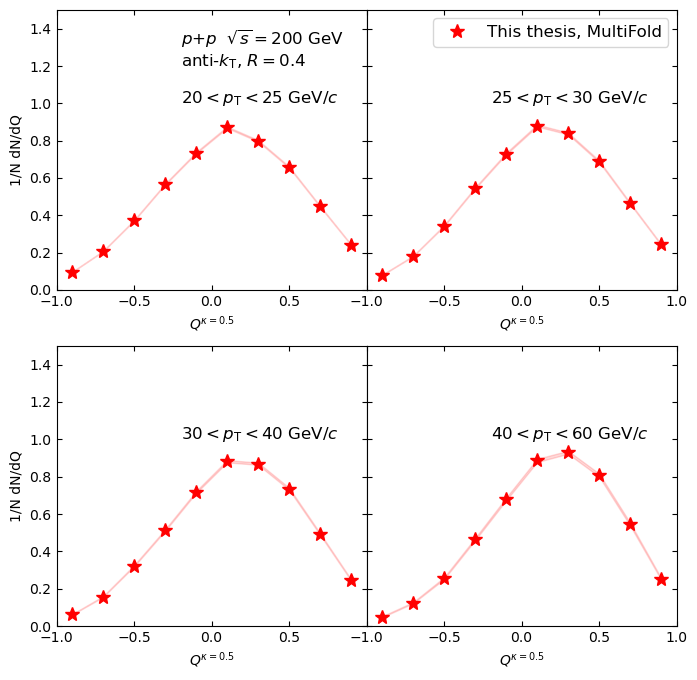

In [38]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

binedges = binedgess[0]
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

ax1 = fig.add_subplot(gs1[0])
plt.text(-0.2,1.2,'$p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(-0.2,1.,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
plt.ylabel('1/N dN/dQ')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax2 = fig.add_subplot(gs1[1])
plt.text(-0.2,1,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(fontsize=12, loc='upper right')

ax3 = fig.add_subplot(gs1[2])
plt.text(-0.2,1,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylabel('1/N dN/dQ')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax4 = fig.add_subplot(gs1[3])
plt.text(-0.2,1,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))